# F5: the oil shock wave on the chain WTI → COP → VLO → DAL

Experiment E4 (540 runs) and the exploratory heterogeneous-herding experiment E4-F (180 runs) on the `graph_chain`
market: three traded companies (COP — oil and gas production, VLO — refining, DAL — airline), oil +20% or −20% at
session 5 (when warmup ends), 120 investors who trade all three companies, two market makers per company.

This notebook reads only K3 run logs (`runs/f5/v1/`, not committed; rerun with
`python -m marketsim.experiments.run configs/f5_e4.yaml --out runs/f5/v1/e4 --workers N`).
The numbers here are **quick-look diagnostics**: the formal wave metrics (transmission, lag, overshoot, half-life)
are D1's (`src/marketsim/metrics/`). Configs and calibration: `docs/guides/f5_graph_valuers.md`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from marketsim.market.api import NO_PRICE
from marketsim.sim.log_schema import load_run

plt.rcParams["figure.dpi"] = 80
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RESULTS = ROOT / "runs" / "f5" / "v1"
SHOCK = 5
TICKERS = ["COP", "VLO", "DAL"]


def session_paths(log):
    """Per session and asset: mean two-sided midpoint, reference and mean valuation (USD)."""
    book = log["book"]
    book = book.loc[(book.best_bid != NO_PRICE) & (book.best_ask != NO_PRICE)]
    book = book.assign(mid=(book.best_bid + book.best_ask) / 200, session=np.floor(book.t).astype(int))
    val = log["valuations"].assign(session=lambda d: np.floor(d.t).astype(int))
    mids = book.groupby(["asset", "session"]).mid.mean().unstack(0)
    ref = (val.groupby(["asset", "session"]).reference.mean() / 100).unstack(0)
    vmean = (val.groupby(["asset", "session"]).v_mean.mean() / 100).unstack(0)
    return mids, ref, vmean


def run_row(log):
    mids, ref, _ = session_paths(log)
    row = {"run_id": log.meta["run_id"], "conserved": log.meta["initial_resources"] == log.meta["final_resources"]}
    for a, t in enumerate(TICKERS):
        m, r = mids[a].reindex(range(30)), ref[a].reindex(range(30))
        move = np.log(r.iloc[-1] / r.iloc[SHOCK - 1])
        row[f"ref_move_{t}"] = move
        for s in range(30):  # share of the reference move reached by the price, per session
            row[f"{t}_{s}"] = np.log(m.iloc[s] / m.iloc[SHOCK - 1]) / move
        after = m.iloc[SHOCK:]
        row[f"dd_{t}"] = float(np.max(1 - after / after.cummax()))
        row[f"err_{t}"] = float(np.mean(np.abs(np.log(after / r.iloc[SHOCK:]))))
    return row


tables = {}
for name in ("e4", "followers"):
    summary = pd.read_csv(RESULTS / name / "summary.csv")
    rows = pd.DataFrame([run_row(load_run(RESULTS / name / rid)) for rid in summary.run_id])
    frame = summary.merge(rows, on="run_id")
    frame["shock"] = frame.external.map({"oil_shock": "+20%", "oil_shock_down": "-20%"})
    frame["crash"] = frame[[f"dd_{t}" for t in TICKERS]].max(axis=1) > 0.25
    tables[name] = frame
e4, fol = tables["e4"], tables["followers"]
print({name: len(frame) for name, frame in tables.items()}, "all resources conserved:",
      all(frame.conserved.all() for frame in tables.values()))
print("empty book side (worst asset), median:", round(e4.filter(like="empty_side").max(axis=1).median(), 3))

{'e4': 540, 'followers': 180} all resources conserved: True
empty book side (worst asset), median: 0.027


## 1. One typical run per shock direction

Mixed investors, h = 0.2. The run is the one whose mean |ln P − ln R| for VLO after the shock is closest to the
median of its cell (chosen by the rule, not by appearance). Solid: price on our exchange; dashed: reference path R
(instant, exact reaction of everyone to the full graph weights); dotted: mean valuation of the valuers.

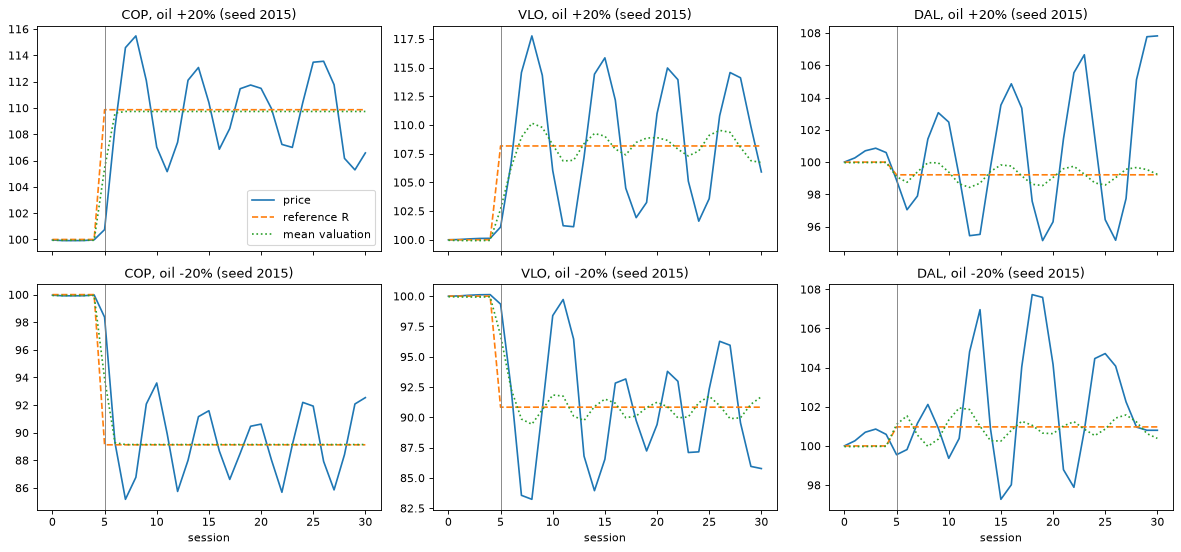

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
for row_axes, shock in zip(axes, ("+20%", "-20%")):
    cell = e4.loc[(e4["agents.composition"] == "mixed") & (e4["agents.herding.h"] == 0.2) & (e4.shock == shock)]
    pick = cell.iloc[(cell.err_VLO - cell.err_VLO.median()).abs().argmin()]
    mids, ref, vmean = session_paths(load_run(RESULTS / "e4" / pick.run_id))
    for a, (ax, t) in enumerate(zip(row_axes, TICKERS)):
        ax.plot(mids.index, mids[a], label="price")
        ax.plot(ref.index, ref[a], "--", label="reference R")
        ax.plot(vmean.index, vmean[a], ":", label="mean valuation")
        ax.axvline(SHOCK, color="grey", lw=0.8)
        ax.set_title(f"{t}, oil {shock} (seed {pick.seed})")
axes[0, 0].legend()
for ax in axes[1]:
    ax.set_xlabel("session")
plt.tight_layout()
plt.show()

## 2. How fast the price follows the reference

Median over non-crash runs (both shock directions; the share is signed so that 1 means "the price moved exactly as
much as R"). DAL is left out: its reference move is only ±0.8% (the airline gains from cheaper oil through the
refiner and loses directly), so its share is dominated by noise.

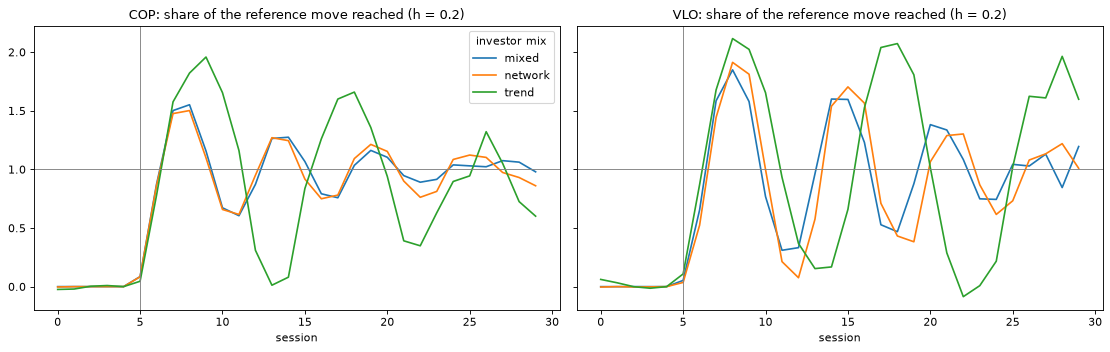

COP 5-6  COP 7-9  COP 10-14  COP 25-29  \
agents.composition agents.herding.h                                           
mixed              0.0                  0.48     1.31       0.97       0.99   
                   0.2                  0.48     1.38       0.95       1.00   
                   0.4                  0.43     1.50       0.93       1.01   
network            0.0                  0.48     1.34       0.96       1.00   
                   0.2                  0.47     1.36       0.96       0.99   
                   0.4                  0.45     1.43       0.94       1.04   
trend              0.0                  0.45     1.61       0.72       1.00   
                   0.2                  0.43     1.64       0.71       0.97   
                   0.4                  0.68     2.51       0.87       1.44   

                                     VLO 5-6  VLO 7-9  VLO 10-14  VLO 25-29  
agents.composition agents.herding.h                                          
mixed              0.0                  0.38     1.54       0.85       0.98  
                   0.2                  0.36     1.67       0.77       0.99  
                   0.4                  0.33     1.72       0.58       0.98  
network            0.0                  0.27     1.66       0.79       1.02  
                   0.2                  0.27     1.72       0.71       1.02  
                   0.4                  0.29     1.88       0.52       0.97  
trend              0.0                  0.39     1.88       0.48       0.93  
                   0.2                  0.50     1.95       0.68       1.49  
                   0.4                  1.05     1.88       0.67       1.26

In [3]:
ok = e4.loc[~e4.crash]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, t in zip(axes, ("COP", "VLO")):
    for comp, group in ok.loc[ok["agents.herding.h"] == 0.2].groupby("agents.composition"):
        ax.plot(range(30), group[[f"{t}_{s}" for s in range(30)]].median(), label=comp)
    ax.axhline(1, color="grey", lw=0.8)
    ax.axvline(SHOCK, color="grey", lw=0.8)
    ax.set_title(f"{t}: share of the reference move reached (h = 0.2)")
    ax.set_xlabel("session")
axes[0].legend(title="investor mix")
plt.tight_layout()
plt.show()

windows = {"5-6": range(5, 7), "7-9": range(7, 10), "10-14": range(10, 15), "25-29": range(25, 30)}
table = {}
for t in ("COP", "VLO"):
    for w, sessions in windows.items():
        ok[f"{t} {w}"] = ok[[f"{t}_{s}" for s in sessions]].mean(axis=1)
        table[f"{t} {w}"] = ok.groupby(["agents.composition", "agents.herding.h"])[f"{t} {w}"].median()
pd.DataFrame(table).round(2)

## 3. Crashes

Share of runs in which some company lost more than 25% from its post-shock peak, although no valuation of any
agent fell that far.

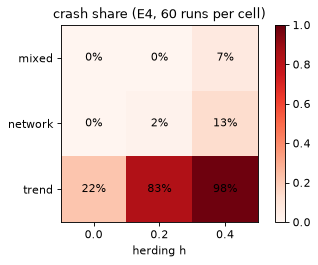

agents.herding.h,0.0,0.2,0.4
agents.composition,,,
mixed,0.00,0.00,0.07
network,0.00,0.02,0.13
trend,0.22,0.83,0.98


In [4]:
crash = e4.pivot_table(index="agents.composition", columns="agents.herding.h", values="crash", aggfunc="mean")
fig, ax = plt.subplots(figsize=(5.5, 3.2))
im = ax.imshow(crash.to_numpy(), cmap="Reds", vmin=0, vmax=1)
ax.set_xticks(range(len(crash.columns)), [str(h) for h in crash.columns])
ax.set_yticks(range(len(crash.index)), crash.index)
for i in range(crash.shape[0]):
    for j in range(crash.shape[1]):
        ax.text(j, i, f"{crash.iat[i, j]:.0%}", ha="center", va="center")
ax.set_xlabel("herding h")
ax.set_title("crash share (E4, 60 runs per cell)")
plt.colorbar(im, ax=ax)
plt.show()
crash.round(2)

## 4. Distance from the reference after the shock

Mean |ln P − ln R| over the 25 post-shock sessions, non-crash runs.

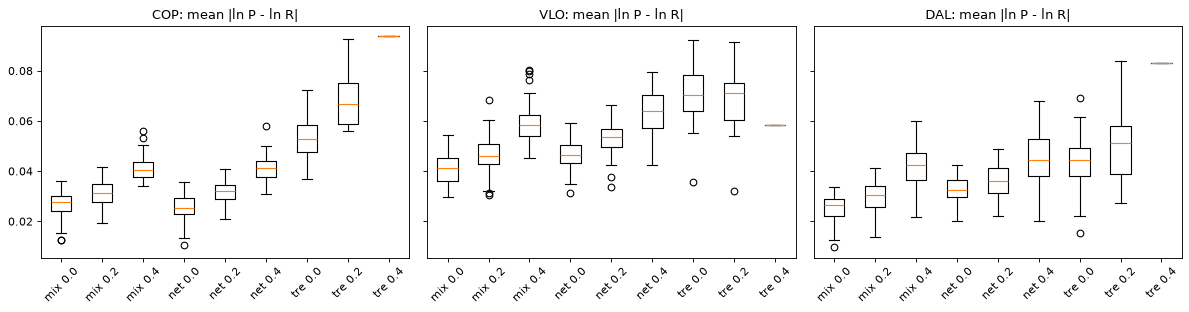

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, t in zip(axes, TICKERS):
    groups = [(f"{c[:3]} {h}", g[f"err_{t}"]) for (c, h), g in ok.groupby(["agents.composition", "agents.herding.h"])]
    ax.boxplot([g for _, g in groups], tick_labels=[n for n, _ in groups])
    ax.set_title(f"{t}: mean |ln P - ln R|")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## 5. Heterogeneous herding (E4-F)

Mixed investors, oil ±20%. A share of investors ("followers") herds with h = 0.6; the others decide alone. Compared
with E4 where every investor has the same h.

In [6]:
fol["mean h"] = 0.6 * fol["agents.herding.followers"]
left = fol.groupby("agents.herding.followers").agg(**{"mean h": ("mean h", "first"), "crash share": ("crash", "mean"),
                                                     "VLO error (median)": ("err_VLO", "median")})
mixed = e4.loc[e4["agents.composition"] == "mixed"]
right = mixed.groupby("agents.herding.h").agg(**{"crash share": ("crash", "mean"), "VLO error (median)": ("err_VLO", "median")})
display(left.round(3))
display(right.round(3))

,mean h,crash share,VLO error (median)
agents.herding.followers,,,
0.25,0.15,0.000,0.042
0.50,0.30,0.000,0.052
1.00,0.60,0.983,0.120


,crash share,VLO error (median)
agents.herding.h,,
0.0,0.000,0.041
0.2,0.000,0.046
0.4,0.067,0.059


## 6. Reading the results

- The wave goes through trades: COP covers about half of its reference move within two sessions, overshoots in
  sessions 7–9 and returns to R; VLO reacts later and overshoots more — the error of the market price of COP is
  passed on by network valuers.
- Herding and trend followers raise both the overshoot and the distance from R; trend-heavy mixes and h = 0.4
  crash often. With h ≥ 0.5 the chain market crashed in most pilot runs, so E4 uses h ∈ {0, 0.2, 0.4}.
- Half of the investors herding at 0.6 behaves like everyone herding at about the mean (0.3); everyone at 0.6 crashes.
- Limits: diagnostics only (no formal metrics yet); 30 sessions; market-maker parameters and the herding grid were
  calibrated on the pilot seeds 1–6 (E4 uses fresh seeds 2001–2030); DAL's reference move is too small to read its
  transmission share.